# 02 · Baseline experiments (E1 hot seat, E5 platform)

**Hypotheses.** H1: the naive read-check-write baseline double-books under contention. H2: every database-enforced strategy produces zero double bookings. H5: an embedded, serial database (PGlite) hides the race.

**Unit of analysis:** the trial (a trial *fails* if any seat is booked more than once).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, RES = ROOT / "data/raw", ROOT / "data/processed", ROOT / "experiments/results"
LOGS, CONFIG = ROOT / "experiments/logs", ROOT / "experiments/configs/experiments.json"

def load_events(run):
    """One row per logged event (op = one transaction attempt, trial = one trial)."""
    return pd.read_json(RAW / run / "events.jsonl", lines=True)

ORDER = ["naive", "conditional_update", "pessimistic_sorted", "pessimistic_unordered",
         "optimistic_version", "serializable", "advisory_lock"]
COLORS = dict(zip(ORDER, ["#d92d20", "#F84464", "#2e90fa", "#7a5af8", "#12b76a", "#f79009", "#667085"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
from statsmodels.stats.proportion import proportion_confint

In [2]:
neon = load_events("main-neon")
T = neon[(neon.type == "trial") & (~neon.warmup.fillna(False).astype(bool))]
e1 = T[T.exp == "E1"]
tab = (e1.assign(failed=e1.doubleBookings > 0)
        .groupby(["strategy", "c"]).agg(trials=("trial", "size"), failed=("failed", "sum"),
                                          winners=("successes", "mean"), double_bookings=("doubleBookings", "sum"))
        .reset_index())
ci = [proportion_confint(f, n, method="wilson") for f, n in zip(tab.failed, tab.trials)]
tab["p_fail"] = tab.failed / tab.trials
tab["wilson_low"], tab["wilson_high"] = zip(*ci)
tab.round(4)

C:\Users\user\AppData\Local\Temp\ipykernel_19868\780803055.py:2: Pandas4Warning: 'bool' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  T = neon[(neon.type == "trial") & (~neon.warmup.fillna(False).astype(bool))]


,strategy,c,trials,failed,winners,double_bookings,p_fail,wilson_low,wilson_high
0,advisory_lock,2.0,20,0,1.0,0.0,0.0,0.0000,0.1611
1,advisory_lock,8.0,20,0,1.0,0.0,0.0,0.0000,0.1611
2,advisory_lock,32.0,20,0,1.0,0.0,0.0,0.0000,0.1611
3,conditional_update,2.0,20,0,1.0,0.0,0.0,0.0000,0.1611
4,conditional_update,8.0,20,0,1.0,0.0,0.0,0.0000,0.1611
5,conditional_update,32.0,20,0,1.0,0.0,0.0,0.0000,0.1611
6,naive,2.0,20,20,2.0,20.0,1.0,0.8389,1.0000
7,naive,8.0,20,20,8.0,140.0,1.0,0.8389,1.0000
8,naive,32.0,20,20,32.0,620.0,1.0,0.8389,1.0000
9,optimistic_version,2.0,20,0,1.0,0.0,0.0,0.0000,0.1611


## H1 — baseline vs. CineBook's conditional UPDATE (Fisher's exact test, all concurrency levels pooled)

In [3]:
def pooled(s):
    d = e1[e1.strategy == s]
    f = int((d.doubleBookings > 0).sum())
    return f, len(d) - f
nf, nok = pooled("naive"); cf, cok = pooled("conditional_update")
odds, p = stats.fisher_exact([[nf, nok], [cf, cok]])
print(f"naive: {nf}/{nf+nok} trials double-booked; conditional_update: {cf}/{cf+cok}")
print(f"Fisher exact p = {p:.3e}")

naive: 60/60 trials double-booked; conditional_update: 0/60
Fisher exact p = 2.070e-35


## H2 — zero double bookings for the six other strategies (E1 + E2)
With 0 failures in *n* trials, the exact one-sided 95% upper bound is 1 − 0.05^(1/n) (≈ 3/n, the *rule of three*).

In [4]:
both = T[T.exp.isin(["E1", "E2"])]
rows = []
for s in ORDER[1:]:
    d = both[both.strategy == s]
    n, dbl = len(d), int(d.doubleBookings.sum())
    rows.append((s, n, dbl, 1 - 0.05 ** (1 / n), 3 / n))
pd.DataFrame(rows, columns=["strategy", "trials", "double_bookings", "exact_upper95", "rule_of_three"]).round(4)

,strategy,trials,double_bookings,exact_upper95,rule_of_three
0,conditional_update,75,0,0.0392,0.04
1,pessimistic_sorted,75,0,0.0392,0.04
2,pessimistic_unordered,75,0,0.0392,0.04
3,optimistic_version,75,0,0.0392,0.04
4,serializable,75,0,0.0392,0.04
5,advisory_lock,60,0,0.0487,0.05


## Sensitivity to concurrency
The baseline's damage scales with the number of simultaneous buyers: every client wins, so double bookings per trial = c − 1.

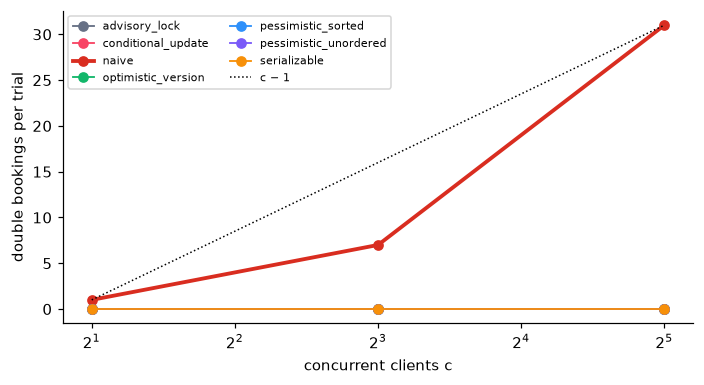

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for s, g in tab.groupby("strategy"):
    ax.plot(g.c, g.double_bookings / g.trials, marker="o", color=COLORS[s], label=s, lw=2.5 if s == "naive" else 1.2)
ax.plot([2, 32], [1, 31], ls=":", color="k", lw=1, label="c − 1")
ax.set_xscale("log", base=2); ax.set_xlabel("concurrent clients c"); ax.set_ylabel("double bookings per trial")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## H5 — platform effect (same naive code, c = 8)

In [6]:
lite = load_events("main-pglite")
L = lite[(lite.type == "trial") & (~lite.warmup.fillna(False).astype(bool)) & (lite.strategy == "naive")]
N = e1[(e1.strategy == "naive") & (e1.c == 8)]
a, b = int((N.doubleBookings > 0).sum()), int((L.doubleBookings > 0).sum())
_, p = stats.fisher_exact([[a, len(N) - a], [b, len(L) - b]])
print(f"Neon: {a}/{len(N)} trials double-booked; PGlite: {b}/{len(L)}; Fisher exact p = {p:.2e}")

Neon: 20/20 trials double-booked; PGlite: 0/15; Fisher exact p = 3.08e-10


C:\Users\user\AppData\Local\Temp\ipykernel_19868\3219408494.py:2: Pandas4Warning: 'bool' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  L = lite[(lite.type == "trial") & (~lite.warmup.fillna(False).astype(bool)) & (lite.strategy == "naive")]


**Reading.** The baseline fails in every contended trial on networked Postgres but never on the embedded, single-connection PGlite, which executes transactions one at a time. A local test suite on an embedded database therefore cannot demonstrate concurrency safety.